In [1]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

In [2]:
import networkx as nx

#  Definizione grafo orientato con NetworkX
G = nx.DiGraph()

## Aggiungi nodi
nodes = [
    ("A", {"bil": -1}),
    ("B", {"bil":  0}),
    ("C", {"bil":  0}),
    ("D", {"bil":  0}),
    ("E", {"bil":  0}),
    ("F", {"bil": +1})
]
G.add_nodes_from(nodes)

## Aggiungi archi (coda, testa, costo)
edges = [
    ("A","B", {"costo":  7}) ,
    ("A","C", {"costo":  8}) ,
    ("B","C", {"costo": -1}) ,
    ("B","D", {"costo":  4}) ,
    ("B","E", {"costo":  1}) ,
    ("B","F", {"costo":  5}) ,
    ("C","F", {"costo":  3}) ,
    ("D","F", {"costo":  1}) ,
    ("E","C", {"costo": -2}) ,
    ("E","D", {"costo":  0}) ,
    ("F","E", {"costo":  3})
]
G.add_edges_from(edges)

for v in G.nodes: # v è l'identificatore del nodo
  print(f"nodo {v} chiede {G.nodes[v]["bil"]}")
for (i,j) in G.edges: # (i,j) è l'identificatore dell'arco
  print(f"arco {i}->{j} costa {G.edges[i,j]["costo"]}")

nodo A chiede -1
nodo B chiede 0
nodo C chiede 0
nodo D chiede 0
nodo E chiede 0
nodo F chiede 1
arco A->B costa 7
arco A->C costa 8
arco B->C costa -1
arco B->D costa 4
arco B->E costa 1
arco B->F costa 5
arco C->F costa 3
arco D->F costa 1
arco E->C costa -2
arco E->D costa 0
arco F->E costa 3


In [3]:
import gurobipy as gp
from gurobipy import GRB

#  Modello Gurobi
m = gp.Model("sp")

# Variabili (archi)
relax_integrality = False
x = m.addVars(G.edges, vtype = GRB.BINARY if not relax_integrality else GRB.CONTINUOUS, name="x")

# Vincoli di bilanciamento
for v in G.nodes:
  inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
  outflow = gp.quicksum(x[v, j] for j in G.successors(v))
  m.addConstr(inflow - outflow == G.nodes[v]["bil"], name=f"balance[{v}]")

# Funzione obiettivo
m.setObjective(gp.quicksum(G.edges[i,j]["costo"] * x[i, j] for (i, j) in G.edges), GRB.MINIMIZE)

m.write("netflow.sp.lp")

# Ottimizza
m.optimize()

# *** MAX HOP ***
maxHop = 2
m.addConstr(gp.quicksum(x[a] for a in G.edges) <= maxHop, name="hop_limit")
m.write("netflow.spH.lp")
m.optimize()


Restricted license - for non-production use only - expires 2028-11-29
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 6 rows, 11 columns and 22 nonzeros (Min)
Model fingerprint: 0xb5c0909e
Model has 10 linear objective coefficients
Variable types: 0 continuous, 11 integer (11 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 12.0000000
Presolve removed 1 rows and 2 columns
Presolve time: 0.00s
Presolved: 5 rows, 9 columns, 18 nonzeros
Variable types: 0 continuous, 9 integer (9 binary)

Root relaxation: objective 9.000000e+00, 3 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds  

In [4]:
#  Risultati
print("\n\nRisultati ottimizzazione:")
archi_in_soluzione = []
if m.status == GRB.OPTIMAL:
  m.setParam("OutputFlag",1)
  m.printAttr("x")
  print(f"Funzione obiettivo = {m.objVal:.6g}")
  print("\nArchi selezionati (x[i,j] == 1):")
  for (i, j) in G.edges:
    if x[i, j].X > 0.5:
      archi_in_soluzione.append((i, j))
      print(f"  {i} -> {j}")



Risultati ottimizzazione:
Set parameter OutputFlag to value 1

    Variable            x 
-------------------------
      x[A,C]            1 
      x[C,F]            1 
Funzione obiettivo = 11

Archi selezionati (x[i,j] == 1):
  A -> C
  C -> F


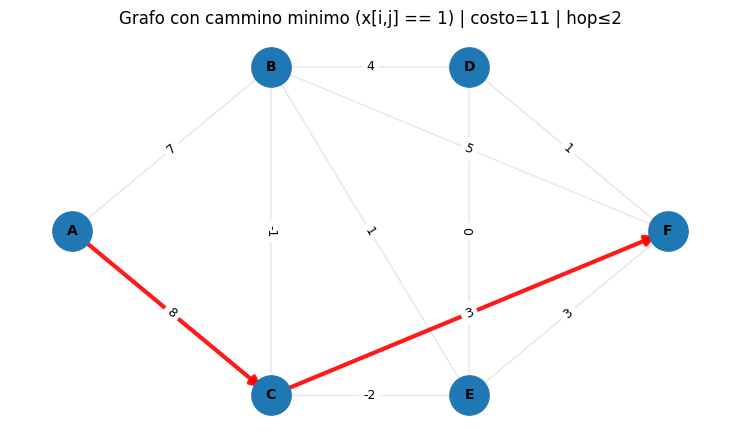

In [5]:
import matplotlib.pyplot as plt

#  Visualizzazione grafo e soluzione

#  Posizioni scelte per i nodi
pos = {
  "A": (0, 2),
  "B": (1.5, 3),
  "C": (1.5, 1),
  "D": (3, 3),
  "E": (3, 1),
  "F": (4.5, 2),
}

plt.figure(figsize=(7.5, 4.5))

# Disegna il grafo (nx lavora sugli assi correnti di matplotlib: brutto ma ce lo teniamo, python permette pure questo)
archi_non_in_soluzione = [e for e in G.edges if e not in archi_in_soluzione]
nx.draw_networkx_edges(G, pos, edgelist=archi_non_in_soluzione, width=1.0, alpha=0.1, arrows=True)

# Disegna gli archi propri della soluzione
if archi_in_soluzione:
  nx.draw_networkx_edges(G, pos, edgelist=archi_in_soluzione, width=3.0, alpha=0.9, arrows=True, arrowsize=15, edge_color="red")

# Nodi e label
nx.draw_networkx_nodes(G, pos, node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

# Etichette dei costi sugli archi
edge_costs = {(u, v): G[u][v]["costo"] for (u, v) in G.edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_costs, font_size=9)

title = "Grafo con cammino minimo (x[i,j] == 1)"
if m.status == GRB.OPTIMAL:
    title += f" | costo={m.objVal:.3g} | hop≤{maxHop}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()